# 7. Synthetic scrapes as training data

Real labeled recordings are few, and each dataset is one setup. What if we could make as many labeled scrapes as
we want, with as many "setups" as we want?

This notebook has a small physics model of a scrape: a rough surface, a tool that slides on it, an object that rings, and a
random recording chain (microphone, phone, accelerometer, room, noise). No real recording is used to build it.

Then two questions:

1. Does a model trained **only** on these sounds recognize the family of real scrapes?
2. Does adding them to the real datasets help the fine-tuning of notebook 6, and does **more** of them help more?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, lfilter, resample_poly, sosfilt
from sklearn.linear_model import LogisticRegression

RATE, SECONDS = 16000, 4.0

## The synthetic scrapes

### Materials and tools

Four kinds of material in each family. For each kind: how rough the surface is, the size and strength of its
regular pattern (wood grain, weave), how hard it is, how many resonances the object has, where they are and how long
they ring, how much of the sound they make, and how often it squeaks or crackles.

In [2]:
# (roughness, pattern period in mm, pattern strength, hardness 0-1, number of resonances, their frequency in Hz,
#  their Q, their share of the sound, chance of stick-slip, chance of crackle)
KINDS = {
    "wood": {
        "hardwood": ((1.3, 1.9), (0.5, 2.0), (0.2, 0.8), 0.7, (8, 20), (200, 3500), (10, 40), (0.3, 0.6), 0.1, 0.1),
        "softwood": ((1.1, 1.6), (1.0, 4.0), (0.5, 1.2), 0.5, (6, 15), (120, 2000), (6, 20), (0.2, 0.5), 0.05, 0.3),
        "plywood": ((1.2, 1.8), (0.3, 3.0), (0.2, 0.9), 0.6, (10, 25), (100, 2500), (8, 25), (0.3, 0.7), 0.1, 0.2),
        "painted wood": ((1.8, 2.5), (0.5, 3.0), (0.0, 0.4), 0.7, (8, 20), (150, 3000), (10, 35), (0.3, 0.6), 0.3, 0.0),
    },
    "metal": {
        "thin sheet": ((1.9, 2.7), (0.03, 0.3), (0.0, 0.6), 1.0, (20, 40), (150, 6000), (100, 800), (0.6, 0.9), 0.3, 0),
        "thick block": ((2.0, 2.8), (0.02, 0.2), (0.0, 0.5), 1.0, (5, 15), (1500, 7800), (300, 2000), (0.4, 0.8), 0.2, 0),
        "brushed": ((1.8, 2.4), (0.01, 0.08), (0.5, 1.2), 1.0, (10, 30), (500, 7500), (200, 1500), (0.5, 0.8), 0.2, 0),
        "rusty or cast": ((1.3, 1.9), (0.05, 0.5), (0.0, 0.4), 0.9, (10, 25), (400, 6000), (80, 600), (0.4, 0.8), 0.1, 0.1),
    },
    "textile": {
        "denim": ((1.0, 1.5), (0.4, 1.2), (0.8, 1.5), 0.2, (0, 2), (100, 600), (1.5, 4), (0.0, 0.1), 0.0, 0.7),
        "felt": ((0.8, 1.3), (0.3, 2.0), (0.0, 0.3), 0.1, (0, 1), (80, 400), (1.5, 3), (0.0, 0.1), 0.0, 0.4),
        "silk-like": ((1.5, 2.2), (0.1, 0.4), (0.3, 0.9), 0.15, (0, 1), (100, 500), (1.5, 3), (0.0, 0.1), 0.1, 0.3),
        "knit": ((1.0, 1.6), (1.0, 4.0), (0.8, 1.5), 0.1, (0, 2), (80, 500), (1.5, 4), (0.0, 0.15), 0.0, 0.8),
    },
    "polymer": {
        "rigid plastic": ((1.8, 2.5), (0.1, 1.0), (0.0, 0.5), 0.75, (6, 15), (300, 5000), (20, 100), (0.3, 0.6), 0.3, 0),
        "rubber": ((1.5, 2.2), (0.2, 2.0), (0.0, 0.6), 0.3, (2, 6), (100, 1500), (3, 10), (0.1, 0.3), 0.8, 0.0),
        "foam": ((0.9, 1.4), (0.5, 3.0), (0.0, 0.4), 0.1, (0, 3), (80, 600), (2, 5), (0.0, 0.2), 0.2, 0.3),
        "vinyl": ((1.7, 2.3), (0.2, 1.5), (0.1, 0.7), 0.5, (4, 10), (200, 3000), (10, 40), (0.2, 0.5), 0.5, 0.0),
    },
}

# (how sharp the contact is, extra stick-slip, resonances of the tool itself)
TOOLS = {
    "steel tip": (1.0, 0.0, None),
    "plastic tip": (0.6, 0.1, None),
    "bare finger": (0.25, 0.2, None),
    "wooden drumstick": (0.5, 0.0, (800, 3000)),
    "rolling ball": (0.4, 0.0, None),
}

### Small bricks

In [3]:
def drawn(rng, bounds, log=False):
    low, high = bounds
    return float(np.exp(rng.uniform(np.log(low), np.log(high)))) if log else float(rng.uniform(low, high))

def coloured_noise(rng, n, exponent):
    spectrum = np.fft.rfft(rng.standard_normal(n))
    frequency = np.maximum(np.arange(len(spectrum)), 1)
    noise = np.fft.irfft(spectrum / frequency ** (exponent / 2), n)
    return noise / noise.std()

def stick_slip(rng, n):
    """Bursts of a periodic slip pulse train (rubber squeak, metal squeal)."""
    out = np.zeros(n)
    for _ in range(rng.integers(1, 4)):
        start, length = rng.integers(0, n // 2), rng.integers(n // 8, n // 2)
        frequency = drawn(rng, (150, 2500), log=True) * (
            1 + 0.02 * np.cumsum(rng.standard_normal(length)) / np.sqrt(length)
        )
        phase = np.cumsum(frequency) / RATE
        train = (np.diff(np.floor(phase), prepend=0) > 0).astype(float)
        out[start : start + length] += train[: n - start] * np.hanning(length)[: n - start]
    return out / (out.std() + 1e-12)

def crackle(rng, n):
    clicks = (rng.random(n) < drawn(rng, (0.0005, 0.005), log=True)) * rng.standard_normal(n)
    return sosfilt(butter(2, [800, 6000], "bandpass", fs=RATE, output="sos"), clicks) * 3

### The tool on the surface

The surface is a random height profile. The tool reads it at a speed that changes during the gesture, and what it
feels is the slope. Harder contacts keep more high frequencies.

In [4]:
def speed_profile(rng, n):
    """Speed along the path for one gesture."""
    t = np.arange(n) / RATE
    base = drawn(rng, (0.005, 0.6), log=True)
    gesture = rng.choice(["straight", "back and forth", "circles"])
    if gesture == "straight":
        return base * (1 + 0.4 * np.sin(2 * np.pi * rng.uniform(0.1, 1) * t + rng.uniform(0, 6)))
    if gesture == "back and forth":  # speed goes through zero at each turn
        return base * np.abs(np.sin(np.pi * rng.uniform(0.5, 3) * t + rng.uniform(0, 3))) * 1.5
    return base * (1 + 0.15 * np.sin(2 * np.pi * rng.uniform(0.5, 3) * t))

def surface_excitation(rng, kind, tool, n):
    beta, period_mm, strength, hardness = kind[0], kind[1], kind[2], kind[3]
    speed = speed_profile(rng, n)
    position_mm = np.cumsum(speed) / RATE * 1000
    grid_mm = 0.005
    length = int(position_mm[-1] / grid_mm) + 2
    profile = coloured_noise(rng, length, drawn(rng, beta))
    period = drawn(rng, period_mm, log=True)
    along = np.arange(length) * grid_mm
    wave = np.sin(2 * np.pi * along / period + 0.3 * np.cumsum(rng.standard_normal(length)) / np.sqrt(length))
    profile += drawn(rng, strength) * np.sign(wave) * np.abs(wave) ** rng.uniform(0.3, 1.5)
    step = int(speed.max() / RATE * 1000 / grid_mm)  # anti-aliasing: smooth details shorter than one sample step
    if step > 1:
        profile = np.convolve(profile, np.ones(step) / step, mode="same")
    height = np.interp(position_mm / grid_mm, np.arange(length), profile)
    excitation = np.diff(height, prepend=height[0])
    cut = np.clip((300 + 7500 * hardness) * TOOLS[tool][0] * rng.uniform(0.6, 1.4), 150, 7900)
    excitation = sosfilt(butter(2, cut, "lowpass", fs=RATE, output="sos"), excitation)
    force = 1 + drawn(rng, (0.05, 0.6)) * np.sin(
        2 * np.pi * rng.uniform(0.2, 3) * np.arange(n) / RATE + rng.uniform(0, 6)
    )
    return excitation / (excitation.std() + 1e-12) * force * np.minimum(speed / speed.mean(), 2) ** 0.5

def mode_bank(rng, count, hz, q, x):
    out = np.zeros_like(x)
    for _ in range(count):
        frequency = drawn(rng, hz, log=True)
        radius = np.exp(-np.pi * frequency / drawn(rng, q, log=True) / RATE)
        out += lfilter(
            [1 - radius], [1, -2 * radius * np.cos(2 * np.pi * frequency / RATE), radius**2], x
        ) * rng.uniform(0.3, 1)
    return out / (out.std() + 1e-12)

### The recording chain

Drawn at random for every sound: the sensor, a low sample rate, an equalizer, one or two noises, bumps, clipping.

In [5]:
def capture(rng, x):
    """A very varied capture chain."""
    n = len(x)
    sensor = rng.choice(["air microphone", "phone", "accelerometer", "piezo", "flat sensor"])
    if sensor == "air microphone":
        distance = drawn(rng, (0.05, 2.0), log=True)  # m; air and distance remove the highs
        x = sosfilt(butter(1, np.clip(8000 / (1 + 2 * distance), 1500, 7900), "lowpass", fs=RATE, output="sos"), x)
        if rng.random() < 0.6:
            tail = np.arange(int(0.6 * RATE)) / RATE
            room = rng.standard_normal(len(tail)) * 10 ** (-3 * tail / drawn(rng, (0.05, 0.8))) * 0.05 * distance
            room[0] = 1
            x = np.convolve(x, room)[:n]
    elif sensor == "phone":
        x = sosfilt(butter(2, drawn(rng, (100, 400)), "highpass", fs=RATE, output="sos"), x)
        if rng.random() < 0.5:  # voice codec band
            x = sosfilt(butter(4, rng.choice([3400, 7000]), "lowpass", fs=RATE, output="sos"), x)
        envelope = np.sqrt(np.convolve(x**2, np.ones(1600) / 1600, mode="same")) + 1e-6
        x = x / envelope ** drawn(rng, (0.3, 0.9))  # automatic gain
        if rng.random() < 0.4:  # noise gate
            x = x * (envelope > np.quantile(envelope, rng.uniform(0.1, 0.4)))
    elif sensor in {"accelerometer", "piezo"}:
        frequency = drawn(rng, (600, 6000), log=True)
        q = drawn(rng, (3, 30), log=True) if sensor == "accelerometer" else drawn(rng, (10, 60), log=True)
        radius = np.exp(-np.pi * frequency / q / RATE)
        x = x + 3 * lfilter([1 - radius], [1, -2 * radius * np.cos(2 * np.pi * frequency / RATE), radius**2], x)
        if sensor == "accelerometer":
            x = sosfilt(butter(4, drawn(rng, (800, 5000), log=True), "lowpass", fs=RATE, output="sos"), x)
        else:
            x = sosfilt(butter(2, drawn(rng, (100, 1000), log=True), "highpass", fs=RATE, output="sos"), x)
    if rng.random() < 0.25:  # a low sample rate somewhere in the chain
        low = int(rng.choice([8000, 11025]))
        x = resample_poly(resample_poly(x, low, RATE), RATE, low)[:n]
    spectrum = np.fft.rfft(x)
    curve = np.interp(np.linspace(0, 1, len(spectrum)), np.linspace(0, 1, 12), rng.uniform(-10, 10, 12))
    x = np.fft.irfft(spectrum * 10 ** (curve / 20), n)
    x = x / (x.std() + 1e-12)
    t = np.arange(n) / RATE
    for _ in range(rng.integers(1, 3)):
        noise = rng.choice(["white", "pink", "brown", "babble", "fan", "mains"])
        if noise in {"white", "pink", "brown"}:
            sound = coloured_noise(rng, n, {"white": 0.0, "pink": 1.0, "brown": 2.0}[noise])
        elif noise == "babble":  # speech-like: band noise with a 3-6 Hz syllable rhythm
            band = sosfilt(butter(2, [200, 3000], "bandpass", fs=RATE, output="sos"), rng.standard_normal(n))
            sound = band * (1 + np.sin(2 * np.pi * rng.uniform(3, 6) * t + 2 * np.sin(2 * np.pi * 0.7 * t)))
        elif noise == "fan":
            sound = coloured_noise(rng, n, 1.0) + np.sin(2 * np.pi * rng.uniform(80, 400) * t)
        else:
            mains = rng.choice([50, 60])
            sound = sum(np.sin(2 * np.pi * mains * k * t) / k for k in range(1, 6))
        x = x + sound / (sound.std() + 1e-12) * 10 ** (-drawn(rng, (0, 40)) / 20)
    if rng.random() < 0.3:
        for start in rng.integers(0, n - 1600, rng.integers(1, 5)):
            x[start : start + 1600] += (
                drawn(rng, (1, 5)) * np.hanning(1600) * np.sin(2 * np.pi * rng.uniform(5, 60) * t[:1600])
            )
    if rng.random() < 0.2:
        peak = np.abs(x).max() * rng.uniform(0.2, 0.7)
        x = np.clip(x, -peak, peak)
    return x

### One scrape

In [6]:
def synthesize(rng, family):
    kind_name = rng.choice(list(KINDS[family]))
    kind = KINDS[family][kind_name]
    tool = rng.choice(list(TOOLS))
    n = int(SECONDS * RATE)
    x = surface_excitation(rng, kind, tool, n)
    if rng.random() < kind[8] + TOOLS[tool][1]:
        x = x + drawn(rng, (0.3, 2.5)) * stick_slip(rng, n)
    if rng.random() < kind[9]:
        x = x + crackle(rng, n) * drawn(rng, (0.3, 2))
    share = drawn(rng, kind[7])
    count = int(rng.integers(kind[4][0], kind[4][1] + 1))
    x = (1 - share) * x / (x.std() + 1e-12) + share * mode_bank(rng, count, kind[5], kind[6], x)
    if TOOLS[tool][2]:  # the drumstick rings too
        x = x + 0.3 * mode_bank(rng, 3, TOOLS[tool][2], (5, 20), x)
    return capture(rng, x), kind_name, tool

## Making 20000 scrapes

5000 per family, 4 s each, cut in windows of 0.5 s like the real recordings. About 15 minutes.
They are kept in memory (2.5 GB), not written to disk.

In [7]:
PER_FAMILY = 5000
FAMILY_NAMES = ["wood", "metal", "textile", "polymer"]

rng = np.random.default_rng(77)
synthetic = np.zeros((4 * PER_FAMILY * 8, RATE // 2), np.float16)
row = 0
for family in FAMILY_NAMES:
    for number in range(PER_FAMILY):
        pieces = synthesize(rng, family)[0].reshape(-1, RATE // 2)
        synthetic[row : row + 8] = pieces / (np.sqrt((pieces**2).mean(axis=1, keepdims=True)) + 1e-12)
        row += 8

synthetic_info = pd.DataFrame({"dataset": "synthetic", "family": np.repeat(FAMILY_NAMES, PER_FAMILY * 8)})
synthetic_info["number"] = np.tile(np.repeat(np.arange(PER_FAMILY), 8), 4)
synthetic_info["recording"] = "synthetic " + synthetic_info.family + " " + synthetic_info.number.astype(str)
synthetic_info["surface"] = synthetic_info.recording
synthetic.shape

(160000, 8000)

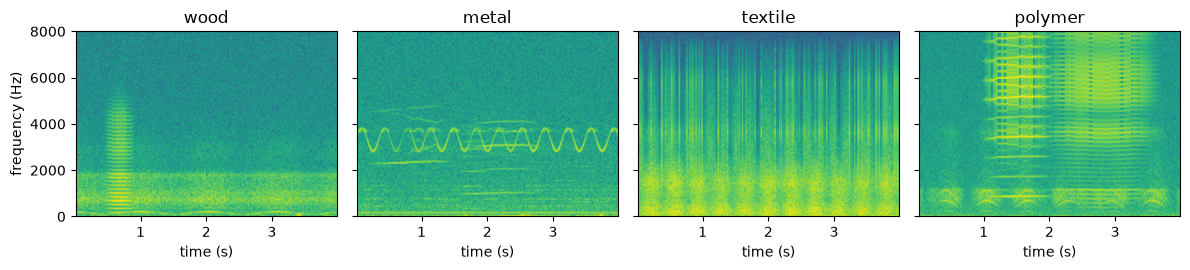

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
rng = np.random.default_rng(1)
for ax, family in zip(axes, FAMILY_NAMES):
    ax.specgram(synthesize(rng, family)[0], NFFT=512, Fs=RATE, noverlap=384)
    ax.set_title(family)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("frequency (Hz)")
plt.tight_layout()
plt.savefig("results/synthetic_examples.png", dpi=120)

## The tools of notebook 6

We reuse the CLAP model and the functions of `6_fine_tuning.ipynb` (`sound_vectors`, `score`, `fine_tune`...).
The next line runs that notebook: it is fast if its tables are already in `results/`.

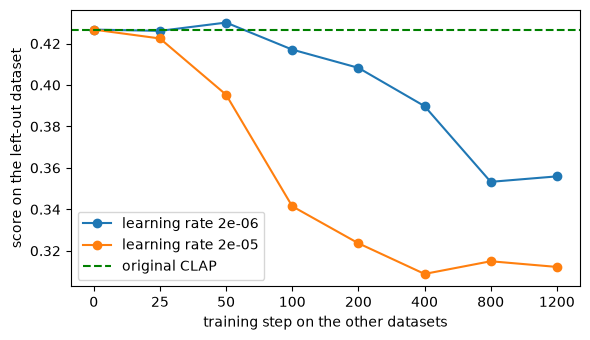

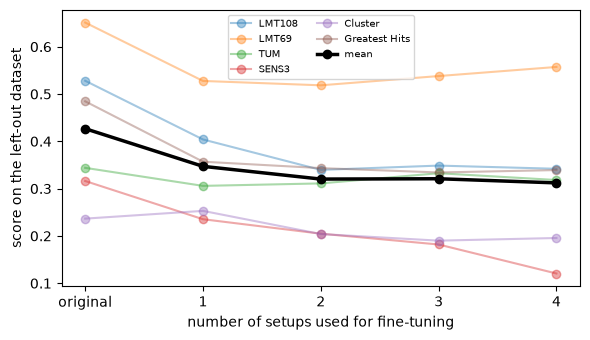

In [9]:
%run 6_fine_tuning.ipynb

real_count = len(windows)
windows = np.concatenate([windows, synthetic])
info = pd.concat([info, synthetic_info], ignore_index=True)
del synthetic

## Question 1: trained only on synthetic scrapes

The first 2000 synthetic scrapes (500 per family). One CLAP vector per sound, a logistic regression on top, and we
test on the real datasets. Vectors are centred inside each dataset, as always.

In [10]:
def vectors_per_recording(rows):
    set_weights(original)
    with torch.no_grad():
        v = torch.cat([sound_vectors(rows[i : i + 32]) for i in range(0, len(rows), 32)]).cpu().numpy()
    means = pd.DataFrame(v).groupby(info.recording[rows].to_numpy()).mean()
    means = means - means.mean()
    return means.div(np.linalg.norm(means, axis=1), axis=0)


train = vectors_per_recording(np.flatnonzero(((info.dataset == "synthetic") & (info.number < 500)).to_numpy()))
family_of = info.drop_duplicates("recording").set_index("recording")
probe = LogisticRegression(max_iter=2000).fit(train, family_of.family[train.index])

rows = []
for d in PUBLIC:
    test = vectors_per_recording(rows_of([d]))
    answers = family_of.loc[test.index].copy()
    families = [f for f in FAMILIES if f in set(answers.family)]
    chances = pd.DataFrame(probe.predict_proba(test), columns=probe.classes_)[families]
    answers["answer"] = np.array(families)[chances.to_numpy().argmax(axis=1)]
    rows.append({"dataset": d, "trained on synthetic only": balanced_draws(answers)})
only_synthetic = pd.DataFrame(rows).set_index("dataset")
only_synthetic.loc["mean"] = only_synthetic.mean()
only_synthetic.round(2)

,trained on synthetic only
dataset,
LMT108,0.46
LMT69,0.44
TUM,0.38
SENS3,0.27
Cluster,0.44
Greatest Hits,0.38
mean,0.39


0.39 on average: a bit above chance, under the 0.43 of CLAP with text prompts and no training at all.

## Question 2: real + synthetic, and does more help?

Same leave-one-dataset-out test as in notebook 6. Half of every training batch is synthetic, half is real.
We use the first 200, 2000 or 20000 synthetic scrapes, so the only thing that changes is how many there are.

In [11]:
rows = saved_rows("results/synthetic_volume.csv")
for target in PUBLIC:
    test = rows_of([target])
    real = rows_of(others(target))
    for per_family in [0, 50, 500, 5000]:
        if any(r["target"] == target and r["synthetic scrapes"] == 4 * per_family for r in rows):
            continue
        fake = np.flatnonzero(((info.dataset == "synthetic") & (info.number < per_family)).to_numpy())
        fine_tune(np.concatenate([real, fake]), half="synthetic" if per_family else None)
        rows.append({"target": target, "synthetic scrapes": 4 * per_family, "score": score(test)})
        pd.DataFrame(rows).to_csv("results/synthetic_volume.csv", index=False)

volume = pd.read_csv("results/synthetic_volume.csv").pivot(index="target", columns="synthetic scrapes", values="score")
volume.loc["mean"] = volume.mean()
volume.round(2)

synthetic scrapes,0,200,2000,20000
target,,,,
Cluster,0.20,0.28,0.26,0.27
Greatest Hits,0.33,0.39,0.42,0.43
LMT108,0.35,0.47,0.47,0.42
LMT69,0.55,0.56,0.56,0.55
SENS3,0.12,0.12,0.11,0.12
TUM,0.32,0.24,0.26,0.26
mean,0.31,0.34,0.35,0.34


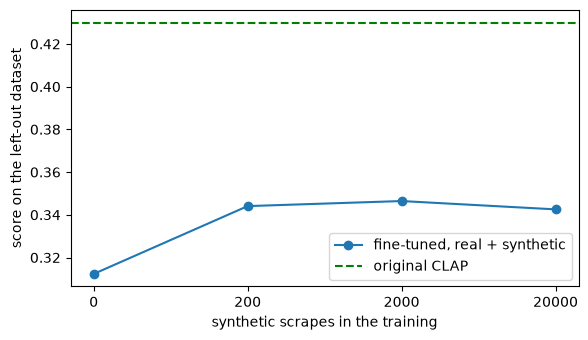

In [12]:
plt.figure(figsize=(6, 3.5))
plt.plot(range(4), volume.loc["mean"], marker="o", label="fine-tuned, real + synthetic")
plt.axhline(0.43, color="green", linestyle="--", label="original CLAP")
plt.xticks(range(4), volume.columns)
plt.xlabel("synthetic scrapes in the training")
plt.ylabel("score on the left-out dataset")
plt.legend()
plt.tight_layout()
plt.savefig("results/synthetic_volume.png", dpi=120)

## What we see

- Trained only on synthetic scrapes, a model does not learn the families of real scrapes.
- Mixed with the real datasets, they help the fine-tuned model a little (0.31 to 0.34), but 20000 scrapes do no
  better than 200.
- Everything stays under the original CLAP.

So the problem of notebook 6 is not the amount of data. Our physics model is also very simple: its sounds were
never checked against real ones.